# ICA: Intermediate Processing Between Pipeline Parts

This notebook can be used to interactively apply Independent Component Analysis (ICA) as an intermediate step between the two preprocessing pipeline parts.

### Workflow

1. **Load** pipeline part-1 output FIF files from the right folder
2. **Fit & Inspect** MNE ICA, determine number of components, visualize components, and select artifact components for exclusion  
3. **Save** cleaned FIF files for pipeline part-2, and ica solution for reproducability

### Naming Convention

Output files must follow: `cleaned_<original_filename_stem>.fif` and `ica-solution_<original_filename_stem>.fif`. This is already coded in this notebook so no need to adjust this.

For example, if your part-1 output is `processed_data-part1_PSEUDOCODE.fif`, it will save the cleaned data as `cleaned_processed_data-part1_PSEUDOCODE.fif`. The pseudocode matching in pipeline part-2 requires the pseudocode to be the last part of the filename starting with an underscore.

### Getting Started

For basic ICA processing, simply modify the values in cells marked with `# --------- ADJUST VALUES BELOW AS NEEDED ---------`.

For advanced usage, explore the [MNE-Python ICA documentation](https://mne.tools/stable/generated/mne.preprocessing.ICA.html) to customize the fitting parameters, component detection, or visualization methods. This notebook is a template for you to adapt. 

#### Source used for this notebook

MNE tutorial [Repairing artifacts with ICA](https://mne.tools/stable/auto_tutorials/preprocessing/40_artifact_correction_ica.html)


In [1]:
# --------- ADJUST VALUES BELOW AS NEEDED ---------

# folder containing part-1 output files (*.fif)
output_dir_part1 = './output_dir'

# folder where ICA-cleaned files and ica solutions are written
output_dir_ica = './output_dir/output_ica'

In [2]:
from pathlib import Path
import mne
from mne.preprocessing import ICA

INPUT_DIR = Path(output_dir_part1)
OUTPUT_DIR = Path(output_dir_ica)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
fif_files = sorted(INPUT_DIR.glob('*.fif'))
if not fif_files:
    raise FileNotFoundError(f'No .fif files found in {INPUT_DIR.resolve()}')

print(f'Found {len(fif_files)} FIF file(s):')
for i, f in enumerate(fif_files):
    print(f'[{i}] {f.name}')

Found 1 FIF file(s):
[0] VBTS_processed_data-part1.fif


In [4]:
def fit_ica_for_inspection(
    file_path: Path,
    n_components=0.99,
    method='fastica',
    random_state=97,
):
    try:
        file_type = mne.what(file_path)
        print(f"The file type is: {file_type}")
        
        # Map the type to the correct reading action
        if file_type == 'raw':
            data = mne.io.read_raw_fif(file_path, preload=True)
        elif file_type == 'epochs':
            data = mne.read_epochs(file_path, preload=True)
            
    except ValueError:
        print("Not a FIF file or the type is not implemented.")

    ica = ICA(n_components=n_components, method=method, random_state=random_state)
    ica.fit(data)

    explained_var_ratio = ica.get_explained_variance_ratio(data)
    for channel_type, ratio in explained_var_ratio.items():
        print(f"Fraction of {channel_type} variance explained by all components: {ratio}")

    print('Inspect the plots and decide which components to exclude.')
    ica.plot_components(inst=data)

    return data, ica

In [5]:
# --------- ADJUST VALUES BELOW AS NEEDED ---------

# Choose from printed list (two cells above)
file_index = 0

# Choose number of components
n_components = 5

# Choose method for ICA ('fastica', 'picard', 'infomax')
method = 'fastica'

The file type is: raw
Opening raw data file output_dir/VBTS_processed_data-part1.fif...
    Range : 0 ... 799999 =      0.000 ...  1599.998 secs
Ready.
Reading 0 ... 799999  =      0.000 ...  1599.998 secs...


/tmp/ipykernel_53029/3857374724.py:13: RuntimeWarning: This filename (output_dir/VBTS_processed_data-part1.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  data = mne.io.read_raw_fif(file_path, preload=True)


Fitting ICA to data using 64 channels (please be patient, this may take a while)
Selecting by number: 5 components
Fitting ICA took 5.7s.
Fraction of eeg variance explained by all components: 0.6403406068918772
Inspect the plots and decide which components to exclude.


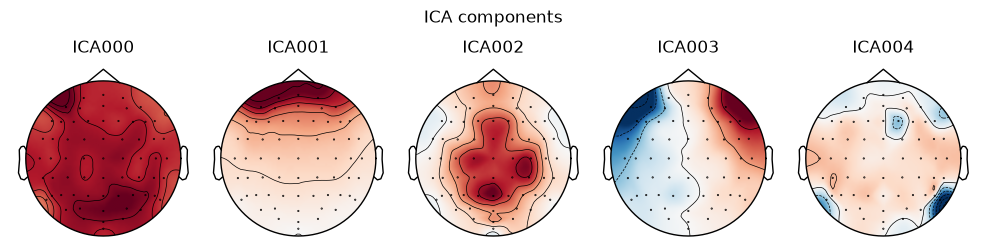

In [6]:
data_instance, ica = fit_ica_for_inspection(
    file_path=fif_files[file_index],
    n_components=n_components,
    method=method,
    random_state=97,
)

In [7]:
# --------- ADJUST VALUES BELOW AS NEEDED ---------

# Set excluded components after visual inspection.
ica.exclude = [1, 3]

Current exclusion list: [1, 3]
Applying ICA to Raw instance
    Transforming to ICA space (5 components)
    Zeroing out 2 ICA components
    Projecting back using 64 PCA components


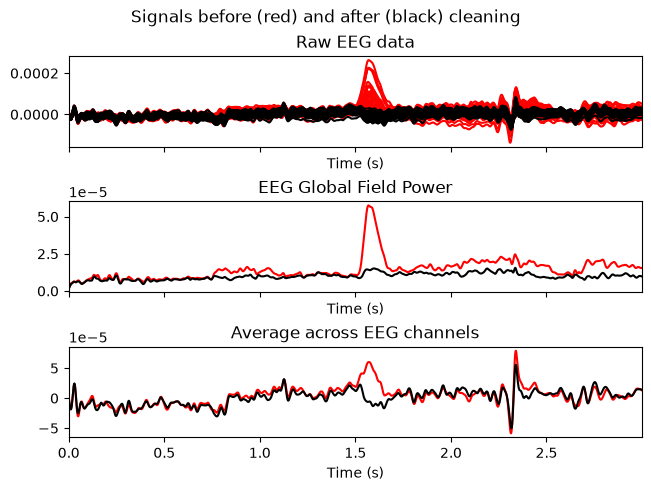

In [8]:
print('Current exclusion list:', ica.exclude)

# Optional deeper inspection for selected components
if isinstance(data_instance, mne.io.Raw):
    ica.plot_overlay(data_instance, ica.exclude)
else:
    ica.plot_overlay(data_instance.average(), ica.exclude)

# ica.plot_sources(data_instance)

In [ ]:
# Apply ICA exclusion and save cleaned output for part-2
cleaned = ica.apply(data_instance.copy())
input_path = fif_files[file_index]
output_path = OUTPUT_DIR / f'cleaned_{input_path.stem}.fif'
ica_object_path = OUTPUT_DIR / 'ica-solutions' / f'ica-solution_{input_path.stem}.fif'
ica_object_path.parent.mkdir(parents=True, exist_ok=True)
ica.save(ica_object_path)
cleaned.save(output_path, overwrite=True)

In [ ]:
print(f'Saved: {output_path.resolve()}')